# Two hydrogen lines, 121.6 nm and 1282 nm: identify them, animate them, and let a "SciNet" answer questions
### SymPy question and answer · reduced-mass (chemically accurate) Rydberg constant · encoder/decoder · slowed-light animation

> **Problem.** Two of the wavelengths emitted by a hydrogen atom are 121.6 nm and 1282 nm.
> Which transitions produce them?

**Answer up front:**

| wavelength | transition | name | photon energy | region |
|---|---|---|---|---|
| 121.6 nm | $n=2\to1$ | Lyman α | 10.20 eV | ultraviolet |
| 1282 nm | $n=5\to3$ | Paschen β | 0.967 eV | infrared |

The rest of this notebook shows *why*, checks it three ways, and animates the two photons leaving
the atom. Everything uses free software; nothing needs to be bought. Every figure uses the Okabe–Ito
colorblind-safe palette, distinguishes curves by line style as well as color, and has a printed
text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
from IPython.display import Image, display
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import hydrogen_lines as h
from dgs import hydrogen_atom as ha
sp.init_printing()

## 1. The method: the Rydberg formula

An electron dropping from level $n$ to level $m<n$ emits one photon with

$$\frac{1}{\lambda}=R_H\left(\frac{1}{m^2}-\frac{1}{n^2}\right).$$

**Strategy for the homework:**
1. Compute $1/(R_H\lambda)$.
2. Find the integers $m<n$ with $1/m^2-1/n^2$ equal to it.
3. Small $m$ means big energy jumps and short wavelengths: $m=1$ is the Lyman series (UV),
   $m=2$ Balmer (visible), $m=3$ Paschen (IR).

SymPy does step 2 exactly, with rational arithmetic:

In [2]:
for lam, n, m, frac, target in h.solve_question_symbolic():
    print(f"lambda = {float(lam):7.1f} nm:  1/(R lambda) = {target:.5f}   best integers n={n}, m={m}:  1/m^2 - 1/n^2 = {frac} = {float(frac):.5f}")

lambda =   121.6 nm:  1/(R lambda) = 0.74981   best integers n=2, m=1:  1/m^2 - 1/n^2 = 3/4 = 0.75000
lambda =  1282.0 nm:  1/(R lambda) = 0.07112   best integers n=5, m=3:  1/m^2 - 1/n^2 = 16/225 = 0.07111


$3/4$ and $16/225$ are the only fractions that fit. You can do this by hand: try $m=1$
($1-1/n^2$ near 0.75 gives $n=2$), then $m=3$ ($1/9-1/n^2\approx0.0711$ gives $1/n^2\approx0.04$,
so $n=5$).

## 2. Check every possible pair, and how sure we are

Search all transitions up to $n=12$ and rank them by error. A big gap to the runner-up means the
assignment is unambiguous:

In [3]:
for lam in (121.6, 1282):
    r = h.identify_line(lam)
    n2, m2, e2 = r["runner_up"]
    print(f"{lam:7.1f} nm -> n={r['n']} -> m={r['m']} ({r['name']}), predicted {r['predicted_nm']:.2f} nm, "
          f"error {r['error_nm']:.2f} nm;  runner-up {n2}->{m2} is off by {e2:.1f} nm;  "
          f"E = {r['energy_eV']:.3f} eV, {r['region']}")

  121.6 nm -> n=2 -> m=1 (Lyman alpha), predicted 121.57 nm, error 0.03 nm;  runner-up 3->1 is off by 19.0 nm;  E = 10.199 eV, ultraviolet
 1282.0 nm -> n=5 -> m=3 (Paschen beta), predicted 1282.17 nm, error 0.17 nm;  runner-up 6->3 is off by 187.9 nm;  E = 0.967 eV, infrared


## 3. "Chemically accurate": the reduced mass

The textbook $R_\infty$ assumes an infinitely heavy nucleus. In reality the electron and proton
orbit their common center of mass, so the electron's mass is replaced by the **reduced mass**
$\mu=m_em_p/(m_e+m_p)$:

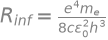

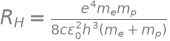

R_H / R_inf - 1/(1 + m_e/m_p) = 0
R_inf = 10,973,731.6 /m    R_H = 10,967,758.3 /m   (0.054% smaller)
2->1: infinite-mass  121.502 nm   reduced-mass  121.568 nm   (repo's hydrogen_atom module, infinite mass:  121.502 nm)
5->3: infinite-mass 1281.469 nm   reduced-mass 1282.167 nm   (repo's hydrogen_atom module, infinite mass: 1281.469 nm)


In [4]:
Rinf, RH, check = h.rydberg_symbolic()
display(sp.Eq(sp.Symbol("R_inf"), Rinf), sp.Eq(sp.Symbol("R_H"), RH))
print("R_H / R_inf - 1/(1 + m_e/m_p) =", check)
print(f"R_inf = {h.R_INF:,.1f} /m    R_H = {h.rydberg_constant():,.1f} /m   (0.054% smaller)")
for n, m in ((2, 1), (5, 3)):
    print(f"{n}->{m}: infinite-mass {h.wavelength_nm(n, m, False):8.3f} nm   reduced-mass {h.wavelength_nm(n, m):8.3f} nm   "
          f"(repo's hydrogen_atom module, infinite mass: {ha.transition_wavelength_nm(n, m):8.3f} nm)")

The correction is about 0.07 nm at 121.6 nm, which is why the given value is 121.6 rather than
121.5. The same correction is how **deuterium** was discovered (Urey, 1932): its heavier nucleus
shifts every line by a tiny, measurable amount.

## 4. A "SciNet" for hydrogen: encoder, latent representation, decoder

This mirrors the machine-discovery figure from the Physics-AI Symbiosis paper:
* **observations:** a list of measured wavelengths;
* **encoder:** compresses them into a **latent representation**, one constant $R$ plus an integer
  pair $(n,m)$ per line;
* **question:** "what wavelength does $n\to m$ produce?"
* **decoder:** answers it from the latent numbers.

Here the encoder is an exact search plus least squares, not a neural network, so every number can
be checked. Feed it six lines computed to full precision:

In [5]:
pairs = [(2, 1), (3, 1), (3, 2), (4, 2), (5, 3), (4, 3)]
obs = [h.wavelength_nm(n, m) for n, m in pairs]
lat = h.encode(obs)
print("latent pairs:", lat["pairs"]); print(f"latent R = {lat['R']:,.2f} /m")
for q in ((6, 2), (7, 3), (3, 2)):
    print(f"question n={q[0]} -> m={q[1]}: answer {h.decode(lat, q):.3f} nm ({h.spectral_region(h.decode(lat, q))})")
print(f"m_p/m_e implied by the fitted R: {1/h.reduced_mass_from_R(lat['R']):.2f}  (true {h.M_P/h.M_E:.2f})")

latent pairs: [(2, 1), (3, 1), (3, 2), (4, 2), (5, 3), (4, 3)]
latent R = 10,967,758.34 /m
question n=6 -> m=2: answer 410.294 nm (visible)
question n=7 -> m=3: answer 1005.219 nm (infrared)
question n=3 -> m=2: answer 656.470 nm (visible)
m_p/m_e implied by the fitted R: 1836.15  (true 1836.15)


The latent constant even "knows" the proton is 1836 times heavier than the electron. But only
if the data are precise enough. Repeat with measurement noise:

wavelength precision 1e-04: inferred m_p/m_e =   1851.5 +/-  234.4
wavelength precision 1e-05: inferred m_p/m_e =   1835.7 +/-   21.3
wavelength precision 1e-06: inferred m_p/m_e =   1836.4 +/-    2.2
wavelength precision 1e-07: inferred m_p/m_e =   1836.1 +/-    0.2


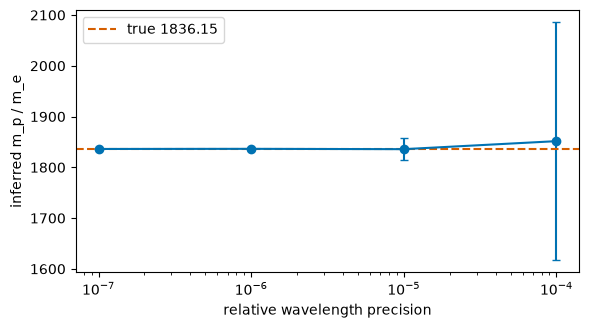

textbook values rounded to 4 digits: m_p/m_e = 1283 -- the rounding swamps the 0.05% effect
Figure description: inferred proton-to-electron mass ratio versus wavelength precision; error bars shrink tenfold per decade of precision and the points settle onto the dashed true value once the precision is about 1e-5 or better.


In [6]:
rng = np.random.default_rng(0); exact = np.array(obs)
rels = [1e-4, 1e-5, 1e-6, 1e-7]; means, stds = [], []
for rel in rels:
    r = [1/h.reduced_mass_from_R(h.encode(exact*(1 + rel*rng.normal(size=6)))["R"]) for _ in range(200)]
    means.append(np.mean(r)); stds.append(np.std(r))
    print(f"wavelength precision {rel:.0e}: inferred m_p/m_e = {np.mean(r):8.1f} +/- {np.std(r):6.1f}")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.errorbar(rels, means, yerr=stds, fmt="o-", color="#0072B2", capsize=3); ax.axhline(h.M_P/h.M_E, ls="--", color="#D55E00", label="true 1836.15")
ax.set_xscale("log"); ax.set_xlabel("relative wavelength precision"); ax.set_ylabel("inferred m_p / m_e"); ax.legend(); plt.show()
lat4 = h.encode([121.6, 102.6, 656.3, 486.1, 1282, 1875])
print(f"textbook values rounded to 4 digits: m_p/m_e = {1/h.reduced_mass_from_R(lat4['R']):.0f} -- the rounding swamps the 0.05% effect")
print("Figure description: inferred proton-to-electron mass ratio versus wavelength precision; error bars shrink tenfold "
      "per decade of precision and the points settle onto the dashed true value once the precision is about 1e-5 or better.")

**Lesson:** a machine, or a person, can only "discover" what the data's precision supports.
You need about six significant figures to see the reduced-mass effect at the 1% level. Real
spectroscopy reaches beyond twelve, which is how hydrogen tests quantum electrodynamics.

## 5. The animation: two photons leaving the atom, with light slowed down

**What it shows:** on the left, the energy ladder, with the electron dropping $2\to1$ (blue) and
$5\to3$ (vermillion). On the right, the two emitted wave packets.

**What's physically accurate:**
* the two wavelengths are drawn in their **true ratio** (1282.2 / 121.6 ≈ 10.5);
* both packets travel at the **same speed** $c$, because all light in vacuum does;
* the energy levels are at their true values.

**What isn't, and is labeled:**
* light is slowed about $10^{17}$ times so it can be watched;
* the atom itself, about 0.1 nm across, can't be drawn on the same scale as 121.6 nm light;
* the Bohr-model ladder gives the right energies but not the right picture of the electron, which
  is a standing-wave cloud, not a dot on a level.

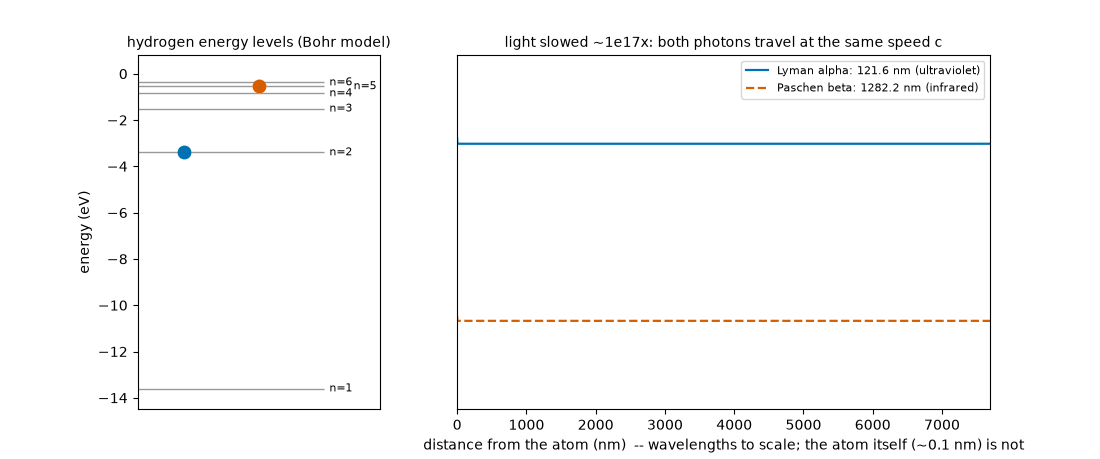

Animation description: Animation. Left: hydrogen energy levels n=1 to 6; an electron drops from n=2 to n=1 and another from n=5 to n=3, each marked by an arrow. Right: two wave packets leave the atom at the same speed; the 121.6 nm wave (solid) has crests about 10.5 times closer together than the 1282.2 nm wave (dashed).


In [7]:
gif = pathlib.Path("hydrogen_emission.gif")
path, alt = h.emission_animation(str(gif), frames=120, fps=24)
display(Image(filename=str(gif)))
print("Animation description:", alt)

## 6. Connections

* **Same physics elsewhere in this repo:**
  - `atomic_clock` (transitions as frequency standards);
  - `frequency_comb` (how such wavelengths are measured to 12+ digits);
  - `nuclide_notation` and `hydrogen_atom` (earlier Knight Chapter 37/38 problems).
* **Slow light for real:** light really can be slowed in matter, by roughly $n_g$ (the group index,
  see `symmetry_phase_limits` Part 2). In atomic vapors near a resonance it has been slowed to
  meters per second using electromagnetically induced transparency. The animation's slowdown is
  just for viewing.

*Education; constants CODATA 2018.*